<a href="https://colab.research.google.com/github/Edohkindness1/sentiment-analysis-tfidf/blob/main/sentiment_classification_final_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Goal:** preprocess raw review text, extract TF-IDF features, and classify polarity (positive / negative) with Multinomial Naive Bayes and Logistic Regression.

**Data note:** the starter file `sentiment_reviews.csv` has only 10 rows (including one neutral review), which is too small to train or benchmark a model. The models are therefore trained on NLTK's 2,000-review movie review corpus (1,000 positive, 1,000 negative). The starter file is kept as a small product-review demo set to show how the model behaves on a different domain.

**Run order:** run all cells top to bottom. The last cell is an interactive input box, so skip it when using "Run all".

## Step 1: Setup

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import joblib

from nltk.corpus import stopwords, movie_reviews
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

for pkg in ["stopwords", "wordnet", "omw-1.4", "punkt", "punkt_tab", "movie_reviews"]:
    nltk.download(pkg, quiet=True)
print("Setup complete")

Setup complete


## Step 2: Load and clean the starter file (demo set)

In [2]:
URL = "https://www.datheon.in/datasets/sentiment_reviews.csv"
try:
    df = pd.read_csv(URL)
    print("Loaded from URL")
except Exception as e:
    print("Direct download failed:", e)
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

TEXT_COL, LABEL_COL = "review_text", "sentiment"
print("Shape:", df.shape)
print("Missing:\n", df[[TEXT_COL, LABEL_COL]].isna().sum())
print("Duplicates:", df.duplicated(subset=[TEXT_COL]).sum())
print("Labels:\n", df[LABEL_COL].value_counts())

df[LABEL_COL] = df[LABEL_COL].astype(str).str.lower().str.strip()
df = df.dropna(subset=[TEXT_COL, LABEL_COL]).drop_duplicates(subset=[TEXT_COL])
df = df[df[LABEL_COL].isin(["positive", "negative"])].reset_index(drop=True)   # drop neutral
df["label"] = df[LABEL_COL].map({"positive": 1, "negative": 0})
print("\nAfter cleaning:", df.shape)
print(df["label"].value_counts())

Loaded from URL
Shape: (10, 3)
Missing:
 review_text    0
sentiment      0
dtype: int64
Duplicates: 0
Labels:
 sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

After cleaning: (9, 4)
label
1    5
0    4
Name: count, dtype: int64


## Step 3: Text preprocessing

Lowercase, remove HTML and URLs, expand contractions, remove punctuation and digits, tokenize, remove stopwords and lemmatize. Negation words (`not`, `no`, `never`, ...) are **kept**, because "not good" must not become "good".

In [3]:
NEGATIONS = {"no", "not", "nor", "never", "don", "dont", "didn", "doesn", "isn", "wasn",
             "aren", "weren", "won", "wouldn", "couldn", "shouldn", "hasn", "haven", "hadn", "cannot"}
STOP = set(stopwords.words("english")) - NEGATIONS
lemmatizer = WordNetLemmatizer()

def expand_contractions(text):
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "cannot", text)
    text = re.sub(r"n't", " not", text)
    return text

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = expand_contractions(text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in STOP and len(t) > 1]
    return " ".join(tokens)

sample = "<br />This movie wasn't GOOD at all!!! I couldn't believe the 3 hours I wasted."
print("Before:", sample)
print("After :", preprocess(sample))

df["clean_text"] = df[TEXT_COL].apply(preprocess)
df[[TEXT_COL, "clean_text", "label"]]

Before: <br />This movie wasn't GOOD at all!!! I couldn't believe the 3 hours I wasted.
After : movie not good could not believe hour wasted


,review_text,clean_text,label
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,1
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,0
2,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,1
3,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,0
4,Customer support helped resolve my setup quest...,customer support helped resolve setup question...,1
5,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable,0
6,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,1
7,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,0
8,Great value and durable build. Would definitel...,great value durable build would definitely pur...,1


## Step 4: Build the training corpus and split (before TF-IDF, to avoid data leakage)

In [4]:
records = [(movie_reviews.raw(fid), 1 if cat == "pos" else 0)
           for cat in movie_reviews.categories()
           for fid in movie_reviews.fileids(cat)]
big_df = pd.DataFrame(records, columns=["review_text", "label"])
big_df = big_df.drop_duplicates(subset="review_text").reset_index(drop=True)
print("Reviews:", big_df.shape[0])
print(big_df["label"].value_counts())

big_df["clean_text"] = big_df["review_text"].apply(preprocess)

X_train, X_test, y_train, y_test = train_test_split(
    big_df["clean_text"], big_df["label"],
    test_size=0.2, stratify=big_df["label"], random_state=RANDOM_STATE)
print("\nTrain:", X_train.shape[0], "| Test:", X_test.shape[0])

Reviews: 2000
label
0    1000
1    1000
Name: count, dtype: int64

Train: 1600 | Test: 400


## Step 5: TF-IDF features (`max_features=5000`)

In [5]:
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)   # fit on training data only
X_test_tfidf = tfidf.transform(X_test)

print("Train matrix:", X_train_tfidf.shape)
print("Test matrix :", X_test_tfidf.shape)
print("Sparsity    : {:.2%}".format(1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape)))

Train matrix: (1600, 5000)
Test matrix : (400, 5000)
Sparsity    : 95.79%


## Step 6: Train and evaluate the baseline models

                         Accuracy  Precision  Recall     F1
Model                                                      
Multinomial Naive Bayes    0.8075     0.8289   0.775  0.801
Logistic Regression        0.8450     0.8194   0.885  0.851

Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       0.79      0.84      0.81       200
    Positive       0.83      0.78      0.80       200

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.88      0.81      0.84       200
    Positive       0.82      0.89      0.85       200

    accuracy                           0.84       400
   macro avg       0.85      0.84      0.84       400
weighted avg       0.85      0.84      0.84       400



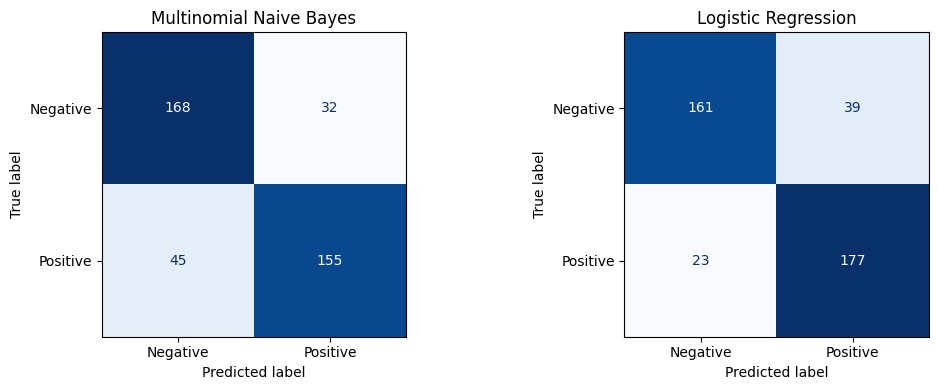

In [6]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE),
}

results, preds = [], {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    preds[name] = y_pred
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, y_pred),
                    "Precision": precision_score(y_test, y_pred),
                    "Recall": recall_score(y_test, y_pred),
                    "F1": f1_score(y_test, y_pred)})

benchmark = pd.DataFrame(results).set_index("Model").round(4)
print(benchmark)

for name, y_pred in preds.items():
    print("\n" + "=" * 55 + "\n" + name + "\n" + "=" * 55)
    print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Negative", "Positive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Step 7: 5-fold cross-validation and strongest words

Multinomial Naive Bayes: folds = [0.805 0.802 0.808 0.822 0.812]
Logistic Regression: folds = [0.85  0.82  0.848 0.825 0.832]

                          Accuracy  Precision  Recall     F1  CV Mean Accuracy  \
Model                                                                           
Multinomial Naive Bayes    0.8075     0.8289   0.775  0.801             0.810   
Logistic Regression        0.8450     0.8194   0.885  0.851             0.835   

                         CV Std  
Model                            
Multinomial Naive Bayes  0.0071  
Logistic Regression      0.0119  


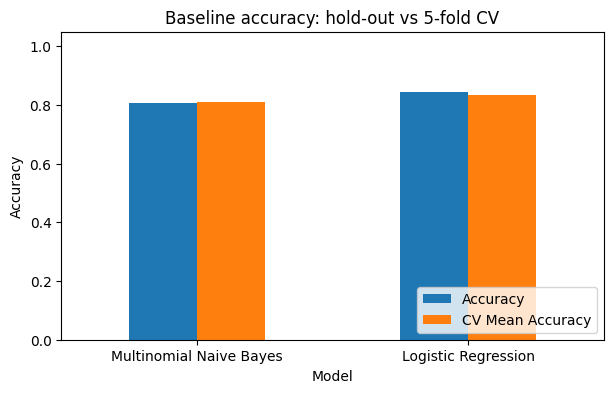


Top NEGATIVE words: bad, worst, plot, not, no, boring, nothing, supposed, script, attempt, stupid, unfortunately, could, harry, look
Top POSITIVE words: great, war, also, performance, life, well, excellent, best, perfect, family, truman, many, mulan, world, overall


In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, clf in {"Multinomial Naive Bayes": MultinomialNB(alpha=1.0),
                  "Logistic Regression": LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE)}.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("clf", clf)])
    scores = cross_val_score(pipe, big_df["clean_text"], big_df["label"], cv=skf, scoring="accuracy")
    cv_rows.append({"Model": name, "CV Mean Accuracy": scores.mean(), "CV Std": scores.std()})
    print(f"{name}: folds = {np.round(scores, 3)}")

final = benchmark.join(pd.DataFrame(cv_rows).set_index("Model").round(4))
print("\n", final)

final[["Accuracy", "CV Mean Accuracy"]].plot(kind="bar", figsize=(7, 4), ylim=(0, 1.05), rot=0)
plt.title("Baseline accuracy: hold-out vs 5-fold CV"); plt.ylabel("Accuracy")
plt.legend(loc="lower right"); plt.show()

lr = models["Logistic Regression"]
feature_names = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
print("\nTop NEGATIVE words:", ", ".join(feature_names[order[:15]]))
print("Top POSITIVE words:", ", ".join(feature_names[order[-15:][::-1]]))

## Step 8: Baseline `predict_sentiment()` helper and demo-set test

In [8]:
best_model = models["Logistic Regression"]

def predict_sentiment(text, model=best_model, vectorizer=tfidf, verbose=True):
    """Return (label, confidence) for a raw review string."""
    cleaned = preprocess(text)
    vec = vectorizer.transform([cleaned])
    if vec.nnz == 0:
        if verbose:
            print(f"Unknown   (no recognised words)  <-  {text}")
        return "Unknown", 0.0
    proba = model.predict_proba(vec)[0]
    label = "Positive" if proba[1] >= 0.5 else "Negative"
    if verbose:
        print(f"{label:9s} ({max(proba):.1%})  <-  {text}")
    return label, float(max(proba))

print("--- Custom phrases ---")
for t in ["This movie was absolutely fantastic, I loved every minute!",
          "Terrible film. Boring plot and awful acting.",
          "The movie was not good at all.",
          "A brilliant, moving and beautifully acted story.",
          "What a waste of time, I want my money back."]:
    predict_sentiment(t)

print("\n--- Starter-file product reviews (different domain) ---")
correct = 0
for text, true_label in zip(df["review_text"], df["label"]):
    label, conf = predict_sentiment(text, verbose=False)
    pred = 1 if label == "Positive" else 0
    correct += (pred == true_label)
    print(f"{'OK ' if pred == true_label else 'XX '} true={'Pos' if true_label else 'Neg'} pred={label:8s} ({conf:.0%})  {text[:60]}")
print(f"\nProduct-review accuracy: {correct}/{len(df)}")

--- Custom phrases ---
Positive  (52.6%)  <-  This movie was absolutely fantastic, I loved every minute!
Negative  (88.0%)  <-  Terrible film. Boring plot and awful acting.
Negative  (70.1%)  <-  The movie was not good at all.
Positive  (69.7%)  <-  A brilliant, moving and beautifully acted story.
Negative  (65.8%)  <-  What a waste of time, I want my money back.

--- Starter-file product reviews (different domain) ---
OK  true=Pos pred=Positive (54%)  The product quality is exceptional, exceeded all my expectat
OK  true=Neg pred=Negative (54%)  Terrible customer service and the item arrived completely da
OK  true=Pos pred=Positive (60%)  Absolutely love this! Easy to setup, robust, and works flawl
XX  true=Neg pred=Positive (59%)  Stopped working after two days. Extremely disappointed with 
XX  true=Pos pred=Negative (51%)  Customer support helped resolve my setup question within ten
XX  true=Neg pred=Positive (52%)  Delivery was slow and package was missing one adapter cable.
OK  tru

## Step 9: Hyperparameter tuning (bigrams, C, alpha)

Grid search runs on the training data only, so the test set stays untouched.

In [9]:
def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("clf", clf)])

searches = {
    "Multinomial Naive Bayes": GridSearchCV(
        make_pipe(MultinomialNB()),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "clf__alpha": [0.1, 0.5, 1.0]},
        cv=5, scoring="accuracy", n_jobs=-1),
    "Logistic Regression": GridSearchCV(
        make_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "clf__C": [0.5, 1, 5, 10]},
        cv=5, scoring="accuracy", n_jobs=-1),
}

tuned, rows = {}, []
for name, gs in searches.items():
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    rows.append({"Model": name, "Best params": gs.best_params_,
                 "CV accuracy": round(gs.best_score_, 4),
                 "Test accuracy": round(accuracy_score(y_test, gs.predict(X_test)), 4)})

tuned_table = pd.DataFrame(rows).set_index("Model")
pd.set_option("display.max_colwidth", None)
print(tuned_table)

best_name = max(tuned, key=lambda n: tuned_table.loc[n, "CV accuracy"])
best_pipe = tuned[best_name]
print("\nBest tuned model:", best_name)

                                                               Best params  \
Model                                                                        
Multinomial Naive Bayes  {'clf__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}   
Logistic Regression           {'clf__C': 10, 'tfidf__ngram_range': (1, 2)}   

                         CV accuracy  Test accuracy  
Model                                                
Multinomial Naive Bayes       0.8244         0.8175  
Logistic Regression           0.8450         0.8575  

Best tuned model: Logistic Regression


## Step 10: Final `predict_sentiment()` helper using the tuned model

In [10]:
def predict_sentiment_final(text, verbose=True):
    """Return (label, confidence) using the tuned pipeline. Confidence near 50% means a coin flip."""
    cleaned = preprocess(text)
    if not cleaned.strip():
        return "Unknown", 0.0
    proba = best_pipe.predict_proba([cleaned])[0]
    label = "Positive" if proba[1] >= 0.5 else "Negative"
    if verbose:
        print(f"{label:9s} ({max(proba):.1%})  <-  {text}")
    return label, float(max(proba))

for t in ["It was not bad", "I was not impressed at all", "This is not good",
          "The battery died within a week, very disappointed",
          "Terrible quality, it broke after one day",
          "Fast delivery and excellent customer service"]:
    predict_sentiment_final(t)

correct = sum((predict_sentiment_final(t, False)[0] == "Positive") == bool(l)
              for t, l in zip(df["review_text"], df["label"]))
print(f"\nStarter-file product reviews: {correct}/{len(df)} correct")

joblib.dump(best_pipe, "sentiment_pipeline.joblib")
print("Saved sentiment_pipeline.joblib")

Negative  (98.9%)  <-  It was not bad
Negative  (64.6%)  <-  I was not impressed at all
Negative  (73.7%)  <-  This is not good
Positive  (55.6%)  <-  The battery died within a week, very disappointed
Negative  (67.1%)  <-  Terrible quality, it broke after one day
Positive  (83.3%)  <-  Fast delivery and excellent customer service

Starter-file product reviews: 5/9 correct
Saved sentiment_pipeline.joblib


## Findings

| Model | Baseline CV acc. | Baseline test acc. | Tuned CV acc. | Tuned test acc. |
|---|---|---|---|---|
| Multinomial Naive Bayes | 0.810 | 0.8075 | 0.8244 | 0.8175 |
| Logistic Regression | 0.835 | 0.8450 | 0.8450 | 0.8575 |

- **Best model:** Logistic Regression with unigrams and bigrams (C=10). It beat Naive Bayes in all 5 baseline cross-validation folds, so the gap is real.
- **Tuning gains were small** (about 1 point of CV accuracy). A test-set gain of 1 point on 400 reviews is roughly 4 to 5 reviews, so it should not be over-interpreted.
- **Negation:** "not good" is handled correctly, but "not bad" is still classified as negative with high confidence. A bag-of-words model adds up word weights and `bad` is strongly negative in movie reviews.
- **Domain shift:** the model scored about 5 to 6 out of 9 on the product reviews, against about 85% on movie reviews, with low confidence (often 51-67%). Product words such as battery, delivery and adapter carry no learned sentiment. Nine reviews is too few to measure accuracy, so this is only an illustration. Fixing it needs product-review training data.
- **Next steps:** train on a larger product-review dataset, try a linear SVM, and consider a transformer model for negation and context.

## Interactive tester

Type your own phrases. Type `quit` to stop. Skip this cell when using Run all.

In [11]:
print("Type a review and press Enter. Type 'quit' to stop.\n")
while True:
    phrase = input("Review: ").strip()
    if phrase.lower() in {"quit", "exit", "q", ""}:
        print("Done.")
        break
    predict_sentiment_final(phrase)

Type a review and press Enter. Type 'quit' to stop.

Review: I absolutely loved this film, it was brilliant
Positive  (89.0%)  <-  I absolutely loved this film, it was brilliant
Review: Terrible quality, it broke after one day
Negative  (67.1%)  <-  Terrible quality, it broke after one day
Review: Fast delivery and excellent customer service
Positive  (83.3%)  <-  Fast delivery and excellent customer service
Review: It was not bad
Negative  (98.9%)  <-  It was not bad
Review: This is not good
Negative  (73.7%)  <-  This is not good
Review: quit
Done.
